<a href="https://colab.research.google.com/github/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02/blob/main/DBTT_05_trainer_huan_luyen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sổ tay 05: Bộ huấn luyện và huấn luyện MLP

**Dự án:** Nhận dạng tham số động cơ PMSM: mạng MLP nhận dạng Ld, Lq theo (id, iq); Rs tính đại số từ Ld, Lq đã nhận dạng.

**Nguyên tắc:** sổ tay chạy độc lập; mỗi lần chạy đều thiết lập lại môi trường từ đầu. Mã được viết, kiểm thử bằng dữ liệu mẫu, xuất thành tệp `.py` rồi đẩy lên GitHub theo bốn bước của PRD.

### Sơ đồ khối của sổ tay (BPMN 2.0, ISO/IEC 19510)



*Hình: Sơ đồ khối quá trình của sổ tay 05*

## Cell 1 – Thiết lập môi trường

In [1]:
# Cell 1 - Thiết lập môi trường từ đầu: gắn Drive, nhận mã truy cập, sao chép kho mã
import os  # Thao tác đường dẫn và tệp
import sys  # Điều chỉnh đường dẫn nạp mô-đun
import subprocess  # Chạy lệnh git và pip
from google.colab import drive, userdata  # Gắn Drive và đọc bí mật của Colab
drive.mount('/content/drive')  # Gắn Google Drive vào phiên Colab
GITHUB_USER = 'maivu18082005-hub'  # Tài khoản GitHub chứa kho mã
REPO_NAME = 'Parameter_Identification_of_PMSM_using_PINN_02'  # Tên kho mã
REPO_DIR = f'/content/{REPO_NAME}'  # Thư mục kho trên máy Colab
TOKEN = userdata.get('GITHUB_TOKEN')  # Mã truy cập lấy từ Colab Secrets
REMOTE = f'https://{TOKEN}@github.com/{GITHUB_USER}/{REPO_NAME}.git'  # Địa chỉ kho kèm mã truy cập


def run(cmd, check=True):  # Hàm chạy lệnh và che mã truy cập trong đầu ra
    r = subprocess.run(cmd, capture_output=True, text=True)  # Chạy lệnh, thu đầu ra
    out = (r.stdout + r.stderr).replace(TOKEN, '***')  # Thay mã truy cập bằng dấu sao
    if check and r.returncode != 0:  # Nếu lệnh lỗi và yêu cầu kiểm tra
        raise RuntimeError(out)  # Báo lỗi kèm đầu ra đã che
    return out  # Trả về đầu ra


def push_files(paths, message):  # Hàm đẩy tệp lên GitHub
    run(['git', '-C', REPO_DIR, 'config', 'user.name', GITHUB_USER])  # Đặt tên người commit
    run(['git', '-C', REPO_DIR, 'config', 'user.email', f'{GITHUB_USER}@users.noreply.github.com'])  # Đặt email người commit
    run(['git', '-C', REPO_DIR, 'add'] + paths)  # Thêm các tệp vào vùng chờ
    if not run(['git', '-C', REPO_DIR, 'status', '--porcelain']).strip():  # Nếu không có thay đổi
        print('Không có thay đổi để đẩy')  # Thông báo
        return  # Kết thúc hàm
    run(['git', '-C', REPO_DIR, 'commit', '-m', message])  # Tạo commit
    run(['git', '-C', REPO_DIR, 'branch', '-M', 'main'])  # Đảm bảo nhánh là main
    run(['git', '-C', REPO_DIR, 'pull', '--rebase', REMOTE, 'main'], check=False)  # Đồng bộ trước khi đẩy
    print(run(['git', '-C', REPO_DIR, 'push', REMOTE, 'HEAD:main']))  # Đẩy lên GitHub


if os.path.isdir(os.path.join(REPO_DIR, '.git')):  # Nếu kho đã có trên máy
    run(['git', '-C', REPO_DIR, 'pull', REMOTE, 'main'], check=False)  # Cập nhật kho
else:  # Nếu chưa có
    run(['git', 'clone', REMOTE, REPO_DIR])  # Sao chép kho từ GitHub
sys.path.insert(0, REPO_DIR)  # Cho phép nạp mô-đun từ kho
TESTS_OK = False  # Cờ cho phép đẩy mã, chỉ bật sau khi kiểm thử đạt
print('Kho mã sẵn sàng tại', REPO_DIR)  # Thông báo hoàn tất

req = os.path.join(REPO_DIR, 'requirements.txt')  # Tệp yêu cầu thư viện
if os.path.exists(req):  # Nếu tệp tồn tại
    run([sys.executable, '-m', 'pip', 'install', '-q', '-r', req])  # Cài thư viện
import torch  # Thư viện học sâu
from src.utils.common import load_config, set_seed, get_paths  # Tiện ích dùng chung
cfg = load_config(os.path.join(REPO_DIR, 'configs', 'config.yaml'))  # Nạp cấu hình
set_seed(cfg['project']['seed'])  # Cố định hạt giống
PATHS = get_paths(cfg)  # Đường dẫn tuyệt đối trên Drive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # Chọn thiết bị tính toán
print('Thiết bị:', DEVICE, '| Torch:', torch.__version__)  # In thông tin môi trường

Mounted at /content/drive
Kho mã sẵn sàng tại /content/Parameter_Identification_of_PMSM_using_PINN_02
Thiết bị: cpu | Torch: 2.14.1+cpu


## Cell 2 – Nạp dữ liệu, thống kê nhãn và kiểm tra điều kiện đầu vào

In [2]:
# Cell 2 - Kiểm tra điều kiện đầu vào và nạp bộ dữ liệu
import copy  # Sao chép cấu hình
import json  # Đọc ghi JSON
import importlib  # Nạp lại mô-đun
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
from src.data.dataset import build_dataloaders  # Hàm dựng bộ nạp dữ liệu
from src.models.ld_lq_mlp import build_mlp, LdLqMLP  # Hàm dựng MLP và lớp mạng
os.makedirs(PATHS['models'], exist_ok=True)  # Đảm bảo thư mục trọng số tồn tại
os.makedirs(PATHS['results'], exist_ok=True)  # Đảm bảo thư mục kết quả tồn tại
assert os.path.exists(os.path.join(PATHS['processed'], 'stats.json')), 'Chạy sổ tay 02 trước để tạo stats.json'  # Dừng nếu thiếu
with open(os.path.join(PATHS['processed'], 'stats.json'), encoding='utf-8') as fh:  # Mở thống kê nhãn
    stats = json.load(fh)  # Đọc thống kê
sets, loaders = build_dataloaders(cfg, PATHS['processed'])  # Dựng tập và bộ nạp
print({k: len(v) for k, v in sets.items()})  # In số mẫu từng tập

[Lọc trùng lặp Train] Giảm từ 899,940 xuống còn 26,292 mẫu (giữ 2.9%)
{'train': 26292, 'val': 299980, 'test': 299980}


## Cell 3 – Viết `src/training/trainer.py`
Hàm mất mát là sai số bình phương trung bình của Ld, Lq sau khi chia cho giá trị tham chiếu `ld_ref`, `lq_ref` (sai số tương đối nên Ld và Lq có trọng số ngang nhau dù chênh độ lớn). Bộ huấn luyện dùng Adam, cắt gradient, giảm tốc độ học theo kiểm định, dừng sớm và lưu điểm tốt nhất.

In [4]:
%%writefile /content/Parameter_Identification_of_PMSM_using_PINN_02/src/training/trainer.py
"""Hàm mất mát và bộ huấn luyện MLP nhận dạng Ld, Lq: tính sai số trung bình (%) ngay trong lúc huấn luyện."""  # Mô tả mô-đun
import json  # Thư viện ghi nhật ký huấn luyện ra tệp JSON
import os  # Thư viện thao tác đường dẫn tệp
import time  # Thư viện đo thời gian chạy
import torch  # Thư viện học sâu PyTorch
import torch.nn as nn  # Các lớp mạng nơ-ron và hàm mất mát của PyTorch


class RelativeMSE(nn.Module):  # Lớp định nghĩa hàm mất mát bình phương tương đối
    """Sai số bình phương trung bình của (Ld, Lq) sau khi chia cho giá trị tham chiếu."""  # Mô tả lớp

    def __init__(self, ref):  # Hàm khởi tạo hàm mất mát
        """Nhận danh sách giá trị tham chiếu (ld_ref, lq_ref) để chuẩn hóa sai số."""  # Mô tả hàm
        super().__init__()  # Gọi hàm khởi tạo của lớp cha nn.Module
        self.register_buffer("ref", torch.tensor(ref, dtype=torch.float32))  # Lưu giá trị tham chiếu vào buffer (không cập nhật gradient)

    def forward(self, pred, target):  # Hàm tính giá trị mất mát
        """Trả về trung bình bình phương sai số tương đối giữa dự đoán và nhãn."""  # Mô tả hàm
        return (((pred - target) / self.ref) ** 2).mean()  # Chia hiệu cho giá trị tham chiếu, bình phương rồi lấy trung bình


def build_loss(cfg):  # Hàm khởi tạo hàm mất mát từ tệp cấu hình
    """Dựng đối tượng RelativeMSE với tham chiếu (ld_ref, lq_ref) từ cấu hình."""  # Mô tả hàm
    m = cfg["motor"]  # Truy cập nhóm thông số động cơ trong cấu hình
    return RelativeMSE([m["ld_ref"], m["lq_ref"]])  # Khởi tạo và trả về hàm mất mát


class Trainer:  # Lớp quản lý quá trình huấn luyện mô hình
    """Huấn luyện mô hình với Adam, cắt gradient, giảm tốc độ học, dừng sớm và theo dõi sai số trung bình (%)."""  # Mô tả lớp

    def __init__(self, model, loss_fn, loaders, cfg, device, save_dir, name):  # Hàm khởi tạo bộ huấn luyện
        """Nhận mô hình, hàm mất mát, bộ nạp dữ liệu, cấu hình, thiết bị và thư mục lưu kết quả."""  # Mô tả hàm
        t = cfg["train"]  # Truy cập nhóm cấu hình huấn luyện
        self.model, self.loss_fn, self.loaders = model.to(device), loss_fn.to(device), loaders  # Chuyển mô hình, hàm mất mát lên thiết bị và lưu bộ nạp
        self.cfg, self.device, self.name = cfg, device, name  # Lưu lại cấu hình, thiết bị tính toán và tên phiên chạy
        self.opt = torch.optim.Adam(self.model.parameters(), lr=t["lr"], weight_decay=t["weight_decay"])
        self.sched = torch.optim.lr_scheduler.ReduceLROnPlateau(self.opt, factor=0.5, patience=max(1, t["patience"] // 3))  # Giảm một nửa tốc độ học khi mất mát kiểm định chững lại
        self.ckpt = os.path.join(save_dir, f"{name}_best.pt")  # Đường dẫn lưu tệp trọng số tốt nhất
        self.history = []  # Danh sách lưu lịch sử các chỉ số qua từng kỷ nguyên

    def _run_epoch(self, split):  # Phương thức chạy một kỷ nguyên trên một tập dữ liệu
        """Chạy một kỷ nguyên trên tập split, trả về (mất mát TB, sai số TB Ld %, sai số TB Lq %)."""  # Mô tả hàm
        train = split == "train"  # Xác định cờ chế độ: True nếu đang huấn luyện, False nếu kiểm định
        self.model.train(train)  # Bật chế độ train (tính gradient) hoặc eval (đánh giá) cho mô hình
        tot_loss, tot_err_ld, tot_err_lq, n = 0.0, 0.0, 0.0, 0  # Khởi tạo các biến cộng dồn mất mát, sai số và tổng số mẫu
        for batch in self.loaders[split]:  # Duyệt qua từng lô dữ liệu trong bộ nạp
            x, y = batch["x"].to(self.device), batch["y"].to(self.device)  # Chuyển tensor đầu vào và nhãn sang CPU/GPU
            with torch.set_grad_enabled(train):  # Chỉ bật tính toán đồ thị gradient khi đang ở tập train
                pred = self.model(x)  # Lan truyền thuận qua mạng MLP để dự đoán (Ld, Lq)
                loss = self.loss_fn(pred, y)  # Tính giá trị hàm mất mát của lô hiện tại
            if train:  # Nếu đang ở giai đoạn huấn luyện
                self.opt.zero_grad()  # Xóa sạch gradient tích lũy từ bước trước
                loss.backward()  # Lan truyền ngược để tính gradient theo các trọng số
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg["train"]["grad_clip"])  # Giới hạn chuẩn gradient để tránh bùng nổ đạo hàm
                self.opt.step()  # Cập nhật trọng số mạng theo thuật toán Adam

            with torch.no_grad():  # Tắt theo dõi gradient khi tính toán chỉ số thống kê sai số
                rel_err = torch.abs(pred - y) / torch.clamp(torch.abs(y), min=1e-12) * 100.0  # Tính sai số tương đối tuyệt đối (%) cho từng mẫu
                tot_err_ld += float(rel_err[:, 0].sum())  # Cộng dồn tổng sai số phần trăm của tham số Ld trong lô
                tot_err_lq += float(rel_err[:, 1].sum())  # Cộng dồn tổng sai số phần trăm của tham số Lq trong lô

            k = x.shape[0]  # Lấy số lượng mẫu thực tế trong lô hiện tại
            tot_loss += float(loss.detach()) * k  # Cộng dồn tổng mất mát có trọng số theo kích thước lô
            n += k  # Cộng dồn tổng số mẫu đã duyệt qua
        return tot_loss / n, tot_err_ld / n, tot_err_lq / n  # Trả về giá trị trung bình trên toàn bộ tập dữ liệu

    def fit(self, print_every=10):  # Phương thức điều khiển vòng lặp huấn luyện chính
        """Huấn luyện tới khi hết số kỷ nguyên hoặc dừng sớm; in sai số trung bình (%) định kỳ."""  # Mô tả hàm
        t, best, wait, t0 = self.cfg["train"], float("inf"), 0, time.time()  # Khởi tạo tham số dừng sớm và mốc thời gian bắt đầu
        for ep in range(t["epochs"]):  # Vòng lặp duyệt qua từng kỷ nguyên huấn luyện
            tr_loss, tr_ld, tr_lq = self._run_epoch("train")  # Chạy một kỷ nguyên trên tập huấn luyện
            va_loss, va_ld, va_lq = self._run_epoch("val")  # Chạy đánh giá trên tập kiểm định
            self.sched.step(va_loss)  # Cập nhật bộ điều chỉnh tốc độ học dựa trên mất mát kiểm định

            record = {  # Đóng gói toàn bộ chỉ số của kỷ nguyên hiện tại vào từ điển
                "epoch": ep,  # Chỉ số kỷ nguyên (tính từ 0)
                "train": tr_loss,  # Mất mát trung bình tập huấn luyện
                "val": va_loss,  # Mất mát trung bình tập kiểm định
                "train_ld_err_pct": tr_ld,  # Sai số tương đối trung bình của Ld trên tập huấn luyện (%)
                "train_lq_err_pct": tr_lq,  # Sai số tương đối trung bình của Lq trên tập huấn luyện (%)
                "val_ld_err_pct": va_ld,  # Sai số tương đối trung bình của Ld trên tập kiểm định (%)
                "val_lq_err_pct": va_lq,  # Sai số tương đối trung bình của Lq trên tập kiểm định (%)
                "lr": self.opt.param_groups[0]["lr"],  # Giá trị tốc độ học hiện tại
            }  # Kết thúc đóng gói bản ghi
            self.history.append(record)  # Thêm bản ghi kỷ nguyên vào danh sách lịch sử

            if ep == 0 or (ep + 1) % print_every == 0:  # In tiến độ ở kỷ nguyên đầu tiên và định kỳ mỗi print_every kỷ nguyên
                print(
                    f"Epoch {ep+1:3d}/{t['epochs']} | "
                    f"Train Err: Ld={tr_ld:.4f}%, Lq={tr_lq:.4f}% | "
                    f"Val Err: Ld={va_ld:.4f}%, Lq={va_lq:.4f}%"
                )  # Hiển thị trực tiếp sai số trung bình (%) của Ld và Lq

            if va_loss < best:  # Nếu mất mát kiểm định đạt mức thấp kỷ lục mới
                best, wait = va_loss, 0  # Cập nhật mức tốt nhất và đặt lại bộ đếm chờ dừng sớm về 0
                self.save()  # Lưu lại trọng số mô hình tốt nhất ra tệp .pt
            else:  # Nếu mất mát kiểm định không cải thiện
                wait += 1  # Tăng bộ đếm số kỷ nguyên chờ đợi thêm 1
            if wait >= t["patience"]:  # Nếu số kỷ nguyên không cải thiện chạm ngưỡng kiên nhẫn
                print(f"Dừng sớm tại epoch {ep+1} | Val Err hiện tại: Ld={va_ld:.4f}%, Lq={va_lq:.4f}%")  # Thông báo kích hoạt dừng sớm
                break  # Thoát khỏi vòng lặp huấn luyện

        if not os.path.exists(self.ckpt):  # Kiểm tra phòng trường hợp chưa có tệp trọng số nào được lưu
            self.save()  # Lưu trạng thái mô hình cuối cùng
        return {"history": self.history, "best_val": best, "seconds": time.time() - t0}  # Trả về lịch sử, mất mát tốt nhất và tổng thời gian chạy

    def save(self):  # Phương thức lưu trọng số mô hình
        """Lưu từ điển trọng số state_dict và cấu hình kiến trúc mạng ra tệp."""  # Mô tả hàm
        torch.save({"state_dict": self.model.state_dict(), "arch": self.model.get_config()}, self.ckpt)  # Ghi tệp checkpoint bằng PyTorch

    def save_history(self, path):  # Phương thức xuất lịch sử huấn luyện
        """Ghi toàn bộ nhật ký huấn luyện qua các kỷ nguyên ra tệp JSON."""  # Mô tả hàm
        with open(path, "w", encoding="utf-8") as f:  # Mở tệp đích ở chế độ ghi mã hóa UTF-8
            json.dump(self.history, f, ensure_ascii=False, indent=1)  # Ghi dữ liệu định dạng JSON dễ đọc

Overwriting /content/Parameter_Identification_of_PMSM_using_PINN_02/src/training/trainer.py


## Cell 4 – Kiểm thử đơn vị trên dữ liệu tổng hợp nhỏ
Kiểm tra mất mát bằng 0 và bằng giá trị đã biết, mất mát huấn luyện giảm, tệp điểm lưu được tạo và nạp lại được, dừng sớm hoạt động và hai lần chạy cùng hạt giống cho cùng kết quả. Dữ liệu tổng hợp có Ld, Lq phụ thuộc trơn vào (id, iq); không dùng dữ liệu thật nên kiểm thử không phụ thuộc Drive.

In [5]:
# Cell 4 - Kiểm thử đơn vị cho trainer.py bằng dữ liệu tổng hợp nhỏ
import tempfile  # Thư mục tạm
from torch.utils.data import Dataset, DataLoader  # Lớp tập dữ liệu và bộ nạp
import src.training.trainer as tr  # Mô-đun cần kiểm thử
importlib.reload(tr)  # Dùng bản mới ghi
ref_t = [cfg['motor']['ld_ref'], cfg['motor']['lq_ref']]  # Giá trị tham chiếu
lf = tr.RelativeMSE(ref_t)  # Hàm mất mát
tgt = torch.tensor([[1.2e-3, 1.4e-3]])  # Nhãn thử
assert float(lf(tgt, tgt)) == 0.0, 'Mất mát phải bằng 0 khi dự đoán đúng'  # Kiểm tra bằng 0
assert abs(float(lf(tgt + torch.tensor([ref_t]) * 0.1, tgt)) - 0.01) < 1e-6, 'Lệch 10% giá trị tham chiếu phải cho mất mát 0,01'  # Kiểm tra giá trị đã biết
assert torch.equal(tr.build_loss(cfg).ref, torch.tensor(ref_t, dtype=torch.float32)), 'build_loss phải lấy ld_ref, lq_ref từ cấu hình'  # Kiểm tra cấu hình


class Synth(Dataset):  # Tập dữ liệu tổng hợp: Ld, Lq giảm trơn theo độ lớn dòng
    def __init__(self, n, seed):  # Hàm khởi tạo
        g = torch.Generator().manual_seed(seed)  # Bộ sinh ngẫu nhiên
        i_d, i_q = -40 * torch.rand(n, generator=g), 60 * torch.rand(n, generator=g)  # Dòng ngẫu nhiên
        ld = 1.3e-3 - 5e-6 * (-i_d) - 2e-6 * i_q  # Ld phụ thuộc id, iq
        lq = 1.5e-3 - 5e-6 * i_q + 2e-6 * i_d  # Lq phụ thuộc id, iq
        self.x, self.y = torch.stack([i_d, i_q], 1), torch.stack([ld, lq], 1)  # Đầu vào và nhãn

    def __len__(self):  # Số mẫu
        return len(self.x)  # Trả về số mẫu

    def __getitem__(self, i):  # Lấy một mẫu
        return {'x': self.x[i], 'y': self.y[i]}  # Gói mẫu


def make_loaders():  # Dựng bộ nạp tổng hợp cố định hạt giống
    return {'train': DataLoader(Synth(1024, 1), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(0)), 'val': DataLoader(Synth(256, 2), batch_size=128)}  # Hai bộ nạp


def make_model(c):  # Dựng MLP với cận đầu ra của dữ liệu tổng hợp
    return LdLqMLP([cfg['motor']['i_rated_peak']] * 2, [0.9e-3, 1.1e-3], [1.4e-3, 1.6e-3], c['model']['hidden_sizes'], c['model']['activation'])  # Dựng mạng


tcfg = copy.deepcopy(cfg)  # Sao chép cấu hình để thử
tcfg['train'].update({'epochs': 40, 'patience': 10, 'batch_size': 128, 'lr': 3e-3})  # Cấu hình huấn luyện ngắn
tmp = tempfile.mkdtemp()  # Thư mục tạm
set_seed(1)  # Cố định hạt giống lần một
t1 = tr.Trainer(make_model(tcfg), tr.build_loss(tcfg), make_loaders(), tcfg, 'cpu', tmp, 'unit')  # Bộ huấn luyện lần một
r1 = t1.fit()  # Huấn luyện
assert r1['history'][-1]['train'] < 0.5 * r1['history'][0]['train'], 'Mất mát huấn luyện phải giảm ít nhất một nửa'  # Kiểm tra giảm
assert os.path.exists(os.path.join(tmp, 'unit_best.pt')), 'Phải có tệp điểm lưu tốt nhất'  # Kiểm tra tệp lưu
ck = torch.load(os.path.join(tmp, 'unit_best.pt'), map_location='cpu')  # Đọc điểm lưu
re = LdLqMLP(**ck['arch'])  # Dựng lại mạng từ kiến trúc đã lưu
re.load_state_dict(ck['state_dict'])  # Nạp trọng số
assert re.get_config() == t1.model.get_config(), 'Điểm lưu phải đủ để dựng lại mạng'  # Kiểm tra kiến trúc
set_seed(1)  # Đặt lại hạt giống
r2 = tr.Trainer(make_model(tcfg), tr.build_loss(tcfg), make_loaders(), tcfg, 'cpu', tmp, 'unit2').fit()  # Huấn luyện lần hai
assert abs(r1['history'][-1]['train'] - r2['history'][-1]['train']) < 1e-9, 'Cùng hạt giống phải cho cùng kết quả'  # Kiểm tra tái lập
scfg = copy.deepcopy(tcfg)  # Cấu hình thử dừng sớm
scfg['train'].update({'epochs': 50, 'patience': 1, 'lr': 0.0})  # Tốc độ học bằng 0 nên kiểm định không cải thiện
r3 = tr.Trainer(make_model(scfg), tr.build_loss(scfg), make_loaders(), scfg, 'cpu', tmp, 'early').fit()  # Huấn luyện thử dừng sớm
assert len(r3['history']) < 10, 'Dừng sớm phải kích hoạt'  # Kiểm tra dừng sớm
TESTS_OK = True  # Bật cờ cho phép đẩy mã
print('Toàn bộ kiểm thử đơn vị đạt')  # Thông báo

Epoch   1/40 | Train Err: Ld=4.6487%, Lq=6.3902% | Val Err: Ld=4.4985%, Lq=5.1971%
Epoch  10/40 | Train Err: Ld=0.3181%, Lq=0.5609% | Val Err: Ld=0.3953%, Lq=0.5190%
Dừng sớm tại epoch 19 | Val Err hiện tại: Ld=0.3833%, Lq=0.5243%
Epoch   1/40 | Train Err: Ld=4.6487%, Lq=6.3902% | Val Err: Ld=4.4985%, Lq=5.1971%
Epoch  10/40 | Train Err: Ld=0.3181%, Lq=0.5609% | Val Err: Ld=0.3953%, Lq=0.5190%
Dừng sớm tại epoch 19 | Val Err hiện tại: Ld=0.3833%, Lq=0.5243%
Epoch   1/50 | Train Err: Ld=6.3639%, Lq=7.3425% | Val Err: Ld=6.0392%, Lq=7.1336%
Dừng sớm tại epoch 2 | Val Err hiện tại: Ld=6.0392%, Lq=7.1336%
Toàn bộ kiểm thử đơn vị đạt


## Cell 5 – Huấn luyện MLP trên dữ liệu thật
Huấn luyện trên Data1–3, kiểm định trên Data4. Sau khi huấn luyện, nạp lại điểm tốt nhất và in sai số tương đối của Ld, Lq trên Data4; việc đánh giá chính thức trên Data5 nằm ở sổ tay 06.

In [6]:
# Cell 5 - Huấn luyện MLP trên dữ liệu thật
import time  # Đo thời gian
set_seed(cfg['project']['seed'])  # Cố định hạt giống
model = build_mlp(cfg, stats)  # Dựng mô hình
trainer = tr.Trainer(model, tr.build_loss(cfg), loaders, cfg, DEVICE, PATHS['models'], 'mlp')  # Dựng bộ huấn luyện
out = trainer.fit()  # Huấn luyện
trainer.save_history(os.path.join(PATHS['results'], 'history_mlp.json'))  # Lưu nhật ký
print('mlp | tham số:', model.count_parameters(), '| số kỷ nguyên:', len(out['history']), '| mất mát kiểm định tốt nhất:', out['best_val'], '| thời gian (s):', round(out['seconds'], 1))  # In tóm tắt
ck = torch.load(trainer.ckpt, map_location=DEVICE)  # Nạp điểm tốt nhất
model.load_state_dict(ck['state_dict'])  # Nạp trọng số
model.eval()  # Chuyển sang chế độ suy luận
with torch.no_grad():  # Tắt gradient
    pv = model(sets['val'].x.to(DEVICE)).cpu().numpy().astype(np.float64)  # Dự đoán trên Data4
yv = sets['val'].y.numpy().astype(np.float64)  # Nhãn Data4
ev = np.abs(pv - yv) / np.abs(yv) * 100.0  # Sai số tương đối (%)
print('Sai số tương đối (%) trên Data4, cột (Ld, Lq): trung bình', ev.mean(0).round(3), '| P95', np.percentile(ev, 95, axis=0).round(3), '| cực đại', ev.max(0).round(3))  # In sai số

Epoch   1/300 | Train Err: Ld=4.8902%, Lq=3.4738% | Val Err: Ld=3.1890%, Lq=2.6927%
Epoch  10/300 | Train Err: Ld=0.6576%, Lq=2.4357% | Val Err: Ld=0.6060%, Lq=1.9928%
Epoch  20/300 | Train Err: Ld=0.6480%, Lq=2.3852% | Val Err: Ld=0.5983%, Lq=1.9203%
Epoch  30/300 | Train Err: Ld=0.6216%, Lq=2.1309% | Val Err: Ld=0.5817%, Lq=1.6646%
Epoch  40/300 | Train Err: Ld=0.6297%, Lq=1.5079% | Val Err: Ld=0.6114%, Lq=1.2081%
Epoch  50/300 | Train Err: Ld=0.6304%, Lq=0.9173% | Val Err: Ld=0.6021%, Lq=0.7648%
Epoch  60/300 | Train Err: Ld=0.6211%, Lq=0.7515% | Val Err: Ld=0.6070%, Lq=0.7104%
Epoch  70/300 | Train Err: Ld=0.6117%, Lq=0.6973% | Val Err: Ld=0.5944%, Lq=0.6099%
Epoch  80/300 | Train Err: Ld=0.6026%, Lq=0.6679% | Val Err: Ld=0.6051%, Lq=0.6027%
Epoch  90/300 | Train Err: Ld=0.6005%, Lq=0.6523% | Val Err: Ld=0.5823%, Lq=0.5858%
Epoch 100/300 | Train Err: Ld=0.5998%, Lq=0.6477% | Val Err: Ld=0.5835%, Lq=0.5468%
Epoch 110/300 | Train Err: Ld=0.5950%, Lq=0.6429% | Val Err: Ld=0.5762%, Lq=

## Cell 6 – Vẽ đường cong mất mát
Mất mát huấn luyện và kiểm định theo kỷ nguyên.

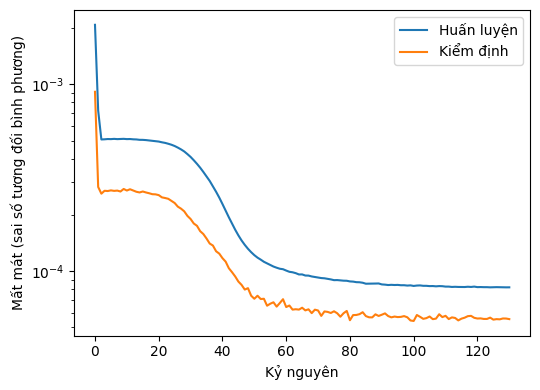

In [7]:
# Cell 6 - Vẽ đường cong mất mát
import matplotlib.pyplot as plt  # Thư viện vẽ đồ thị
h = pd.DataFrame(out['history'])  # Nhật ký thành bảng
fig, ax = plt.subplots(figsize=(5.5, 4))  # Một đồ thị
ax.semilogy(h['epoch'], h['train'], label='Huấn luyện')  # Mất mát huấn luyện
ax.semilogy(h['epoch'], h['val'], label='Kiểm định')  # Mất mát kiểm định
ax.set_xlabel('Kỷ nguyên')  # Nhãn trục hoành
ax.set_ylabel('Mất mát (sai số tương đối bình phương)')  # Nhãn trục tung
ax.legend()  # Chú giải
fig.tight_layout()  # Căn chỉnh bố cục
fig.savefig(os.path.join(PATHS['results'], 'loss_curves.png'), dpi=150)  # Lưu ảnh vào Drive
plt.show()  # Hiển thị ảnh

## Cell 7 – Khảo sát kiến trúc (tùy chọn)
Quét độ rộng và độ sâu lớp ẩn với số kỷ nguyên rút gọn. Đặt `RUN_SWEEP = True` để chạy; kết quả lưu vào `sweep.csv`. Số kỷ nguyên khảo sát `[TBD]`. Chọn kiến trúc theo mất mát kiểm định (Data4), không dùng Data5.

In [8]:
# Cell 7 - Khảo sát kiến trúc (tùy chọn)
RUN_SWEEP = False  # [TBD] Đặt True để chạy khảo sát kiến trúc
SWEEP_EPOCHS = 60  # [TBD] Số kỷ nguyên rút gọn khi khảo sát
rows = []  # Danh sách kết quả khảo sát
if RUN_SWEEP:  # Nếu bật khảo sát
    for hs in ([16, 16], [32, 32], [64, 64], [32, 32, 32]):  # Duyệt các kiến trúc ứng viên
        sc = copy.deepcopy(cfg)  # Sao chép cấu hình
        sc['model']['hidden_sizes'], sc['train']['epochs'] = hs, SWEEP_EPOCHS  # Đặt kiến trúc và số kỷ nguyên
        set_seed(sc['project']['seed'])  # Cố định hạt giống
        mdl = build_mlp(sc, stats)  # Dựng MLP ứng viên
        res = tr.Trainer(mdl, tr.build_loss(sc), loaders, sc, DEVICE, tempfile.mkdtemp(), 'sweep').fit()  # Huấn luyện
        rows.append({'hidden': str(hs), 'params': mdl.count_parameters(), 'best_val': res['best_val']})  # Ghi kết quả
    sweep = pd.DataFrame(rows)  # Bảng kết quả
    sweep.to_csv(os.path.join(PATHS['results'], 'sweep.csv'), index=False)  # Lưu vào Drive
    display(sweep)  # Hiển thị bảng
else:  # Nếu không bật
    print('Bỏ qua khảo sát kiến trúc')  # Thông báo

Bỏ qua khảo sát kiến trúc


## Cell 8 – Bước 4: đẩy lên GitHub
Chỉ mã nguồn được đẩy; trọng số và nhật ký nằm trên Drive.

In [9]:
# Cell cuối - Bước 4: đẩy tệp đã kiểm thử đạt lên GitHub
assert TESTS_OK, 'Chưa đạt toàn bộ kiểm thử, không được đẩy mã'  # Chặn đẩy mã khi kiểm thử chưa đạt
push_files(['src/training/trainer.py'], 'Thêm trainer.py')  # Đẩy các tệp lên nhánh main

To https://github.com/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02.git
   4504c29..6dd462b  HEAD -> main

